In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import importlib
import pandas as pd

import data_loaders

importlib.reload(data_loaders)

<module 'data_loaders' from 'C:\\Beryllium Base\\WORKSPACES\\MTECH\\RS-project\\src\\data_loaders\\__init__.py'>

In [3]:
data_model = data_loaders.MindData(root='../data/mind')
behaviours = data_model.behaviours
behaviours.memory_usage(deep=True).sum() // 1024 // 1024, 'MB'

(np.int64(1719), 'MB')

In [4]:
behaviours.head()

,impression_id,user_id,time,history,impressions
0,1,U87243,11/10/2019 11:30:54 AM,N8668 N39081 N65259 N79529 N73408 N43615 N2937...,N78206-0 N26368-0 N7578-0 N58592-0 N19858-0 N5...
1,2,U598644,11/12/2019 1:45:29 PM,N56056 N8726 N70353 N67998 N83823 N111108 N107...,N47996-0 N82719-0 N117066-0 N8491-0 N123784-0 ...
2,3,U532401,11/13/2019 11:23:03 AM,N128643 N87446 N122948 N9375 N82348 N129412 N5...,N103852-0 N53474-0 N127836-0 N47925-1
3,4,U593596,11/12/2019 12:24:09 PM,N31043 N39592 N4104 N8223 N114581 N92747 N1207...,N38902-0 N76434-0 N71593-0 N100073-0 N108736-0...
4,5,U239687,11/14/2019 8:03:01 PM,N65250 N122359 N71723 N53796 N41663 N41484 N11...,N76209-0 N48841-0 N67937-0 N62235-0 N6307-0 N3...


In [6]:
n_unique_users = behaviours['user_id'].unique().size
n_unique_users, 100 * n_unique_users // behaviours.size

(711222, 6)

['U536528', 'U569581', 'U41536', 'U301043', 'U483745', 'U155504', 'U489942', 'U176820', 'U686458', 'U90793', 'U572245', 'U297213', 'U497035', 'U558804', 'U609133', 'U57014', 'U255796', 'U641296', 'U706557', 'U611442']


<Axes: xlabel='user_id'>

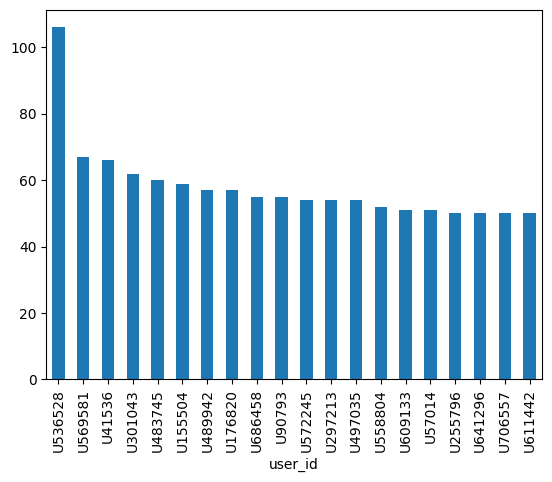

In [39]:
user_counts = behaviours['user_id'].value_counts()
top_users = behaviours['user_id'].value_counts().head(20)
print(list(top_users.index))
top_users.plot(kind='bar')

In [40]:
most_frequent_user = 'U536528'

In [41]:
user_data = behaviours[behaviours['user_id'] == most_frequent_user]
user_data['time'] = pd.to_datetime(user_data['time'])
user_data = user_data.sort_values(by='time')
user_data = user_data.set_index('time')
print(user_data.size)
user_data.head()

424


,impression_id,user_id,history,impressions
time,,,,
2019-11-09 05:00:10,33987,U536528,N59450 N90402 N27587 N109736 N43373 N125282 N9...,N32622-0 N86149-0 N43186-0 N65783-0 N10012-0 N...
2019-11-09 05:02:11,862460,U536528,N59450 N90402 N27587 N109736 N43373 N125282 N9...,N118589-1 N65783-0
2019-11-09 05:02:26,2103025,U536528,N59450 N90402 N27587 N109736 N43373 N125282 N9...,N118589-1 N65783-0
2019-11-09 05:02:37,1114428,U536528,N59450 N90402 N27587 N109736 N43373 N125282 N9...,N118589-1 N65783-0
2019-11-09 05:02:51,1847573,U536528,N59450 N90402 N27587 N109736 N43373 N125282 N9...,N65783-0 N118589-1


np.float64(5229.0)

<Axes: xlabel='time'>

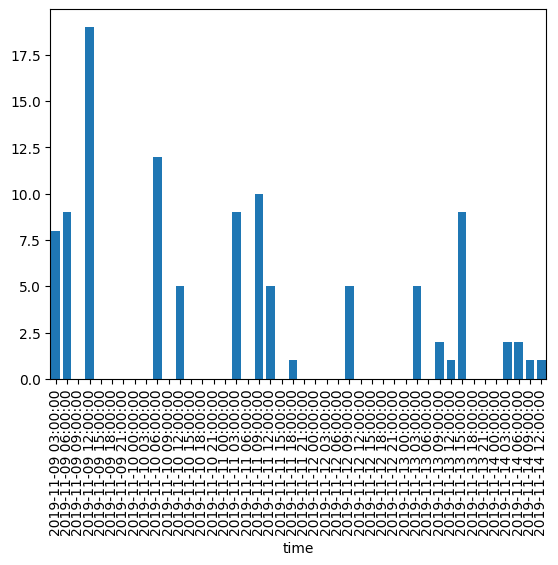

In [55]:
resampled_user_data = user_data.resample('3h').size()
resampled_user_data.plot(kind='bar', width=100/len(resampled_user_data))

In [51]:
len(resampled_user_data)

44

In [59]:
data_model.news.head()

,news_id,category,subcategory,title,abstract,url,title_entities,abstract_entities
0,N88753,lifestyle,lifestyleroyals,"The Brands Queen Elizabeth, Prince Charles, an...","Shop the notebooks, jackets, and more that the...",https://assets.msn.com/labs/mind/AAGH0ET.html,"[{""Label"": ""Prince Philip, Duke of Edinburgh"",...",[]
1,N45436,news,newsscienceandtechnology,Walmart Slashes Prices on Last-Generation iPads,Apple's new iPad releases bring big deals on l...,https://assets.msn.com/labs/mind/AABmf2I.html,"[{""Label"": ""IPad"", ""Type"": ""J"", ""WikidataId"": ...","[{""Label"": ""IPad"", ""Type"": ""J"", ""WikidataId"": ..."
2,N23144,health,weightloss,50 Worst Habits For Belly Fat,These seemingly harmless habits are holding yo...,https://assets.msn.com/labs/mind/AAB19MK.html,"[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik...","[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik..."
3,N86255,health,medical,Dispose of unwanted prescription drugs during ...,NaN,https://assets.msn.com/labs/mind/AAISxPN.html,"[{""Label"": ""Drug Enforcement Administration"", ...",[]
4,N93187,news,newsworld,The Cost of Trump's Aid Freeze in the Trenches...,Lt. Ivan Molchanets peeked over a parapet of s...,https://assets.msn.com/labs/mind/AAJgNsz.html,[],"[{""Label"": ""Ukraine"", ""Type"": ""G"", ""WikidataId..."


711222